## <span style="color:purple"> Graph Yearly Temperature-Salinity Plots for Each MicroCAT </span>

<span style="color:purple"> These graphs will plot temperature against salinity data from across the year. The purpose of this is to visually inspect the composition of the water masses that are recorded at a particular MicroCAT, which should allow for some interpretation of their source. </span>

### <span style="color:purple"> Plotting function </span>

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import gsw

# # Define a dictionary mapping each season to a distinctive colourmap and their month numbers
season_cmaps = {
    "Summer (Dec–Feb)": ("Reds",   [12, 1, 2]),
    "Autumn (Mar–May)": ("YlOrBr", [3, 4, 5]),
    "Winter (Jun–Aug)": ("Blues",  [6, 7, 8]),
    "Spring (Sep–Nov)": ("Greens", [9, 10, 11]),
}

# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
avg_pressures = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 653.6,    "4054": 861.5,   "3883": 1211.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}

def plot_ts_year(df, borehole, cat, year, ylim_temp=None, xlim_sal=None):
    # Create a mask to filter the dataframe for the specified borehole and cat
    mask = (df["borehole"] == borehole) & (df["cat"] == cat)
    sub = df[mask].copy()
    
    # Create a mask for the year including the December the year before, and excluding the December of the same year
    year_mask = (((sub["time"].dt.year == year - 1) & (sub["time"].dt.month == 12)) | ((sub["time"].dt.year == year) & (sub["time"].dt.month <= 11)))
    sub = sub[year_mask].copy()
    if sub.empty:
        print(f"No data for {borehole} cat{cat} in austral year {year}")
        return

    # Extract day of year and year from the time column
    sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440

    # Create to filter the dataframe to just December timestamps
    dec_mask = sub["time"].dt.month == 12
    # Create boolean variable that represents whether the actual year Dec sits in is a leap year or not
    leap_year = sub.loc[dec_mask, "time"].dt.is_leap_year
    # Shift December DOY negative so it sits before January
    sub.loc[dec_mask, "doy"] -= leap_year.map({True: 366, False: 365})
    
    # Extract the position of the iterated MicroCAT in the water column at its respective borehole
    position = sub["water_column_position"].dropna().iloc[0]

    # sharex=True to share the x-axis between the two subplots
    fig, ax = plt.subplots(figsize=(10, 10))

    # Plot each season with its own colourmap, normalised to that season's DOY range
    # Iterate over each season and its respective colourmap and months in season_cmaps
    for season_name, (cmap_name, months) in season_cmaps.items():
        # Filter the dataframe to include only the months included in the iterated season
        season_data = sub[sub["time"].dt.month.isin(months)]

        # Extract the colourmap
        cmap = plt.get_cmap(cmap_name)
        
        doy_min = season_data["doy"].min()
        doy_max = season_data["doy"].max()
        # Normalise the DOY values to the range 0.3 to 0.1
        # Avoid the lightest end of the cmap (given that is hard to see) — start at 0.3
        norm_doy = 0.3 + 0.7 * (season_data["doy"] - doy_min) / (doy_max - doy_min)

        ax.scatter(season_data["absolute_salinity"], season_data["conservative_temperature"], c=cmap(norm_doy), s=2, label=season_name)

    # Plot different overlays to aid in identifying and interpreting the source water masses
    # Define the range of temp and salinity over which we will plot these
    salinity_range = np.linspace(xlim_sal[0], xlim_sal[1], 100)
    temp_range = np.linspace(ylim_temp[0], ylim_temp[1], 100)
    pressure_average = avg_pressures[f"{cat}"]

    # 1. Freezing point temperature line at 0 dbar (saturation fraction = 0)
    CT_freeze_0 = gsw.CT_freezing(salinity_range, 0, 0)
    ax.plot(salinity_range, CT_freeze_0, "b--", lw=1, label=r"$\Theta_f$ (0 dbar)")

    # 2. Freezing point temperature line at average mooring pressure (determined at deployment)
    CT_freeze_p = gsw.CT_freezing(salinity_range, pressure_average, 0)
    ax.plot(salinity_range, CT_freeze_p, "b-", lw=1, label=fr"$\Theta_f$ ({pressure_average:.0f} dbar)")

    # 3. Isopycnals (potential density anomaly contours) referenced to 0 dbar
    # This is the anomaly, i.e. density minus 1000 kg/m^3 (appropriate for shallowish waters)
    salinity_grid, temp_grid = np.meshgrid(salinity_range, temp_range)
    sigma = gsw.sigma0(salinity_grid, temp_grid)
    cs = ax.contour(salinity_grid, temp_grid, sigma, colors="grey", linestyles=":", linewidths=0.6)
    ax.clabel(cs, inline=True, fontsize=7, fmt="%.2f")

    # 4. Meltwater (Gade) line — anchored at warmest/saltiest source water
    salinity_source = sub["absolute_salinity"].quantile(0.95)
    temp_source = sub["conservative_temperature"].quantile(0.95)
    # Ice temperature: in situ freezing temperature at source pressure
    t_ice = gsw.t_freezing(salinity_source, pressure_average, 0)
        
    # Get dSA/dCT from gsw, invert to get dCT/dSA for plotting
    dSA_dCT = gsw.ice.melting_ice_SA_CT_ratio(salinity_source, temp_source, pressure_average, t_ice)
    slope = 1 / dSA_dCT  # dCT/dSA
        
    CT_gade = temp_source + slope * (salinity_range - salinity_source)
    ax.plot(salinity_range, CT_gade, "k-", lw=1.5, label="Meltwater mixing line")
    ax.plot(salinity_source, temp_source, "ko", markersize=6)
    
    ax.set_ylabel(r"$\Theta$ (°C)")
    ax.set_xlabel(r"$\mathrm{S_{A} \ g \ kg^{-1}}$")
    ax.set_title(f"{borehole} {position.capitalize()} MicroCAT cat{cat}: Temperature vs. Salinity for Austral Year {year}")

    ax.legend(loc="best", fontsize=8)

    if ylim_temp is not None: ax.set_ylim(*ylim_temp)
    if xlim_sal  is not None: ax.set_xlim(*xlim_sal)

    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Plot yearly temperature vs. salinity plots for each borehole/cat </span>

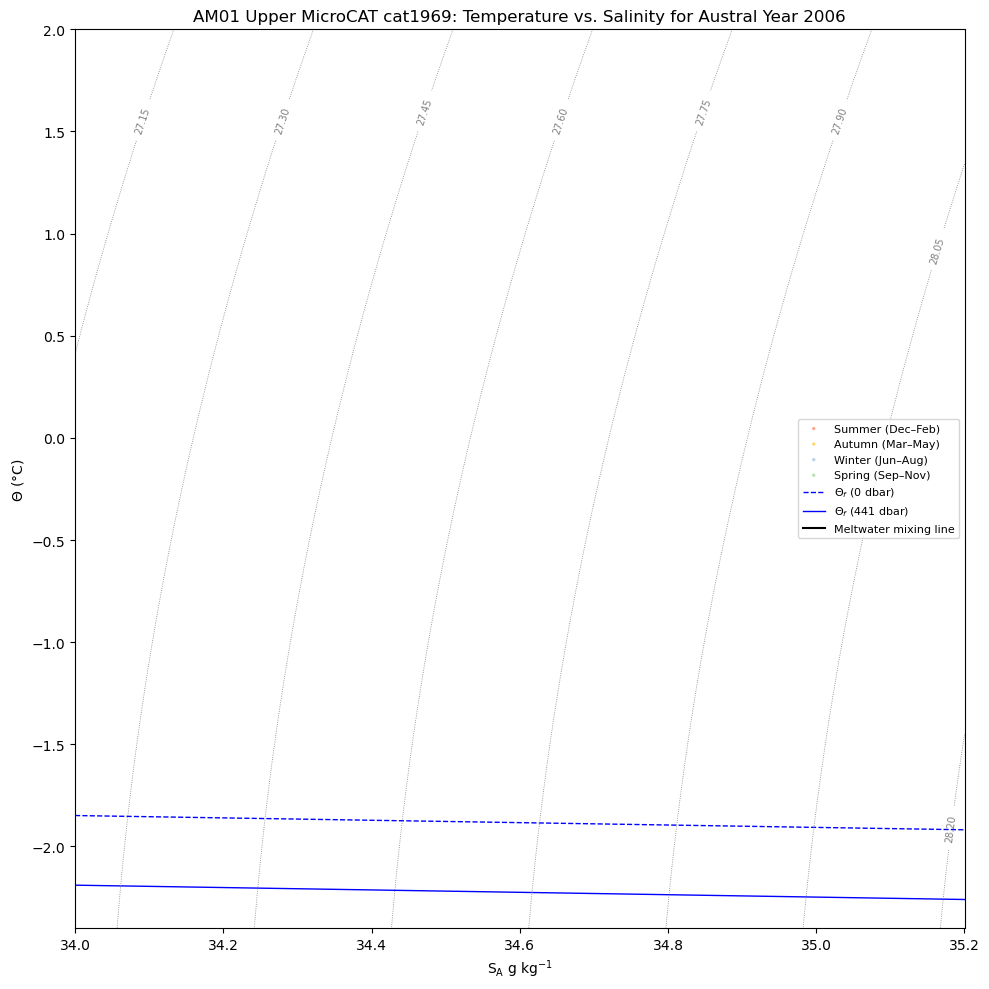

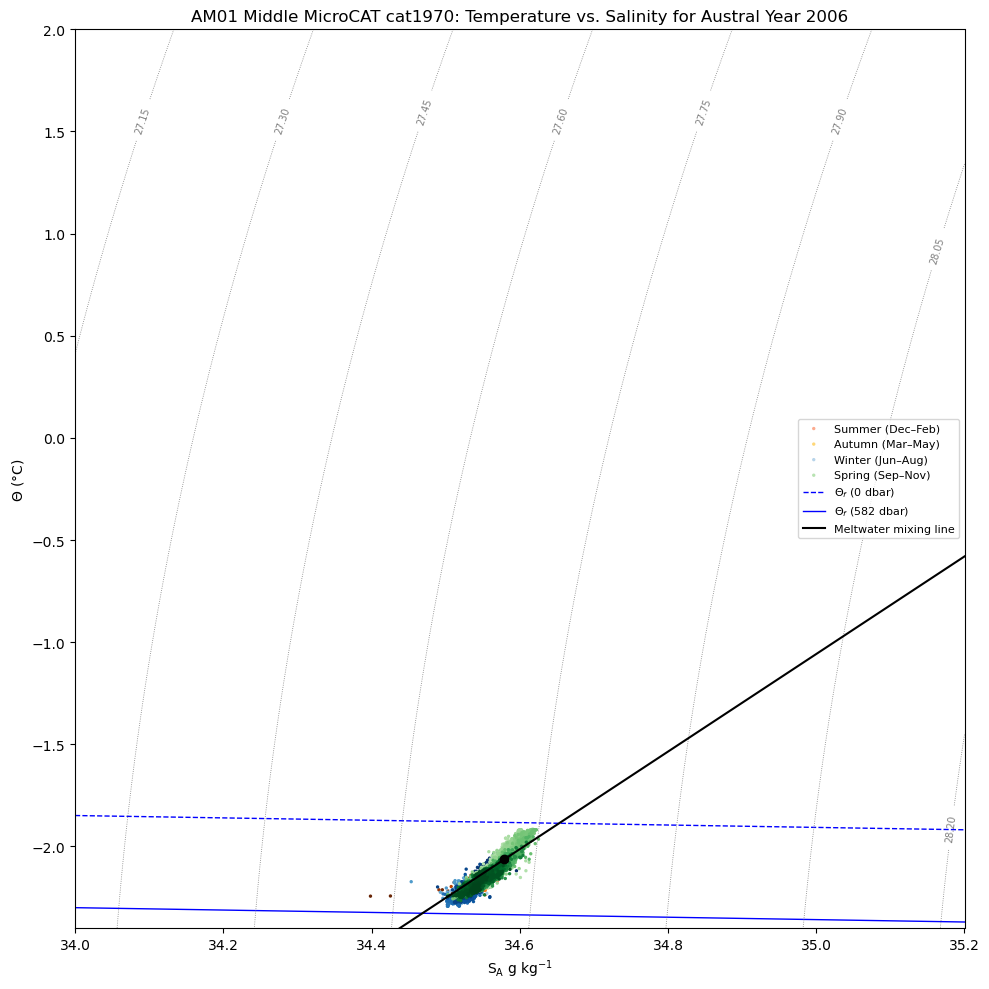

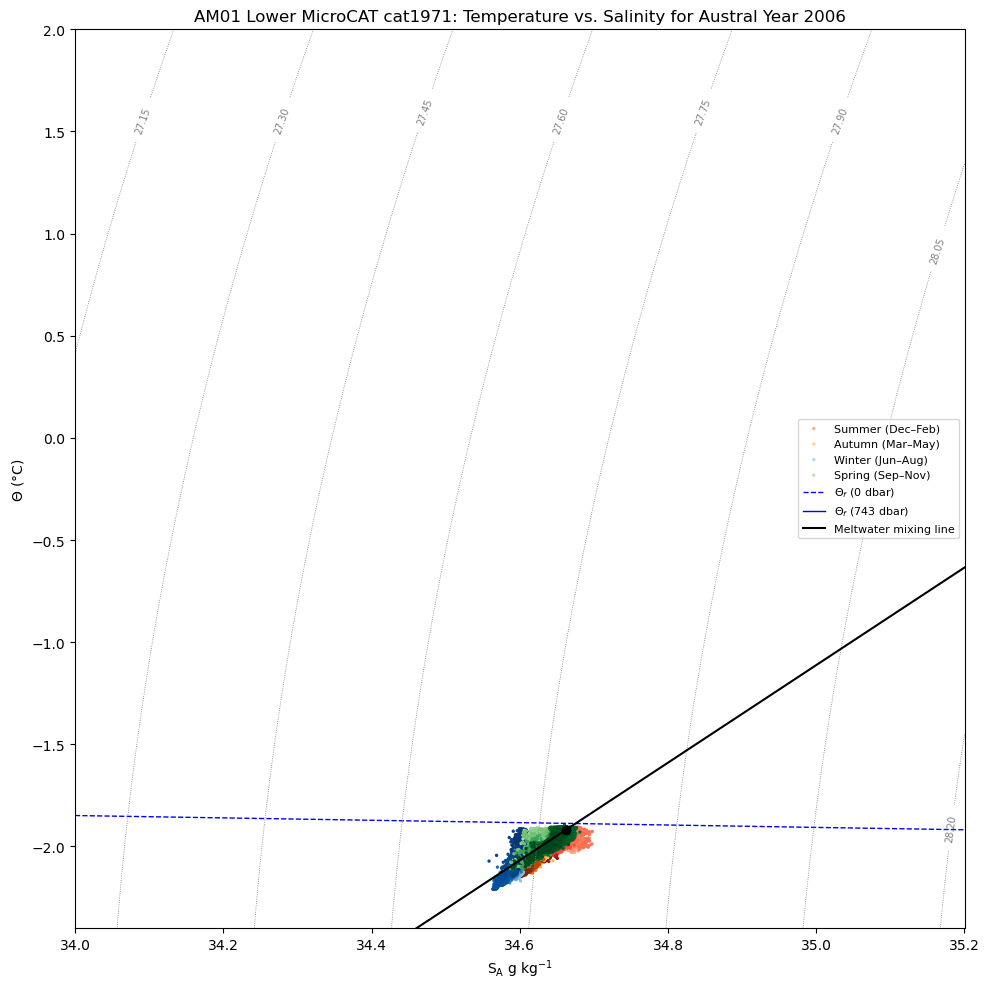

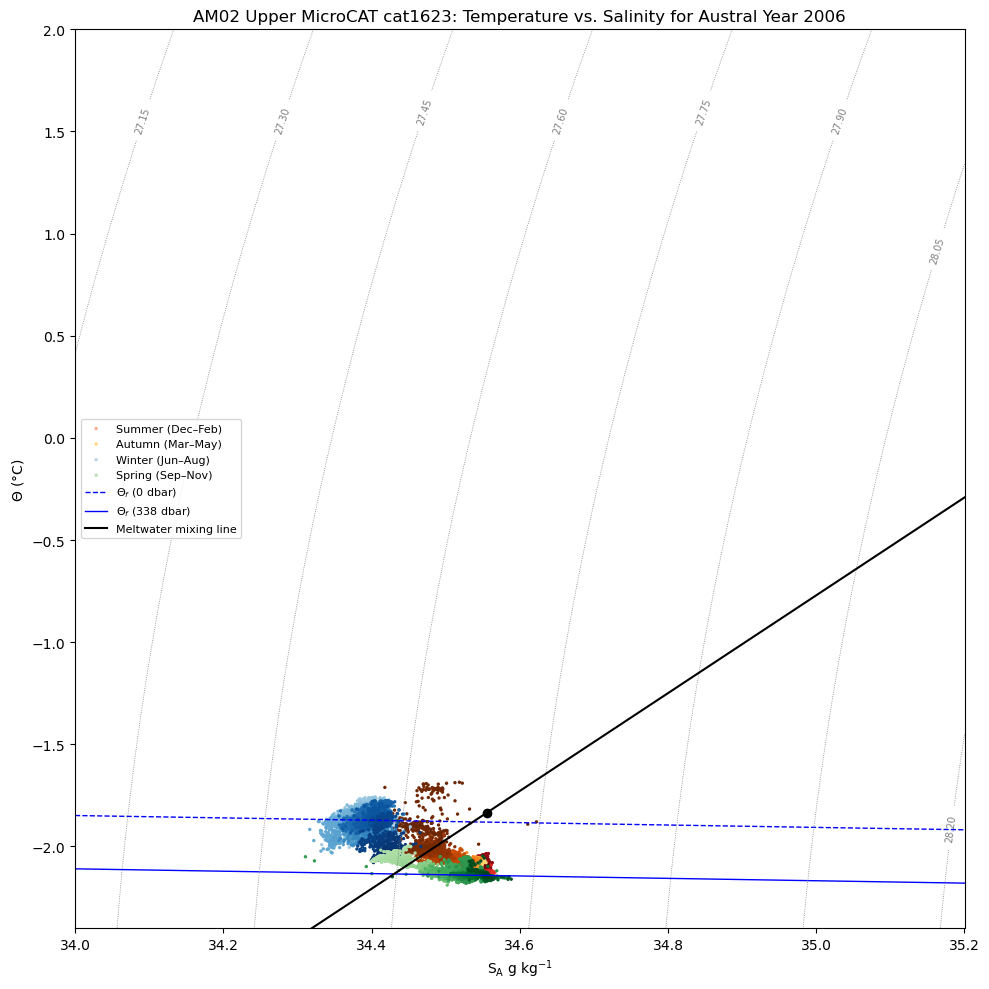

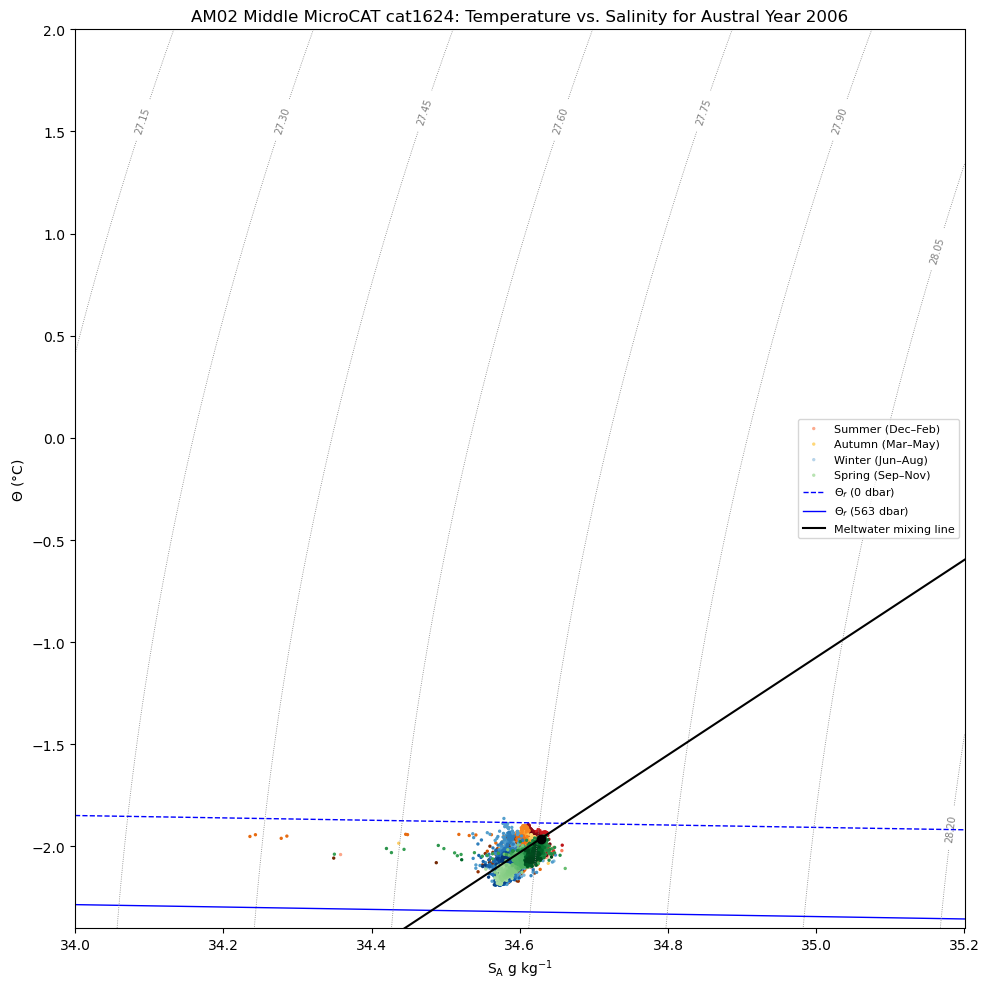

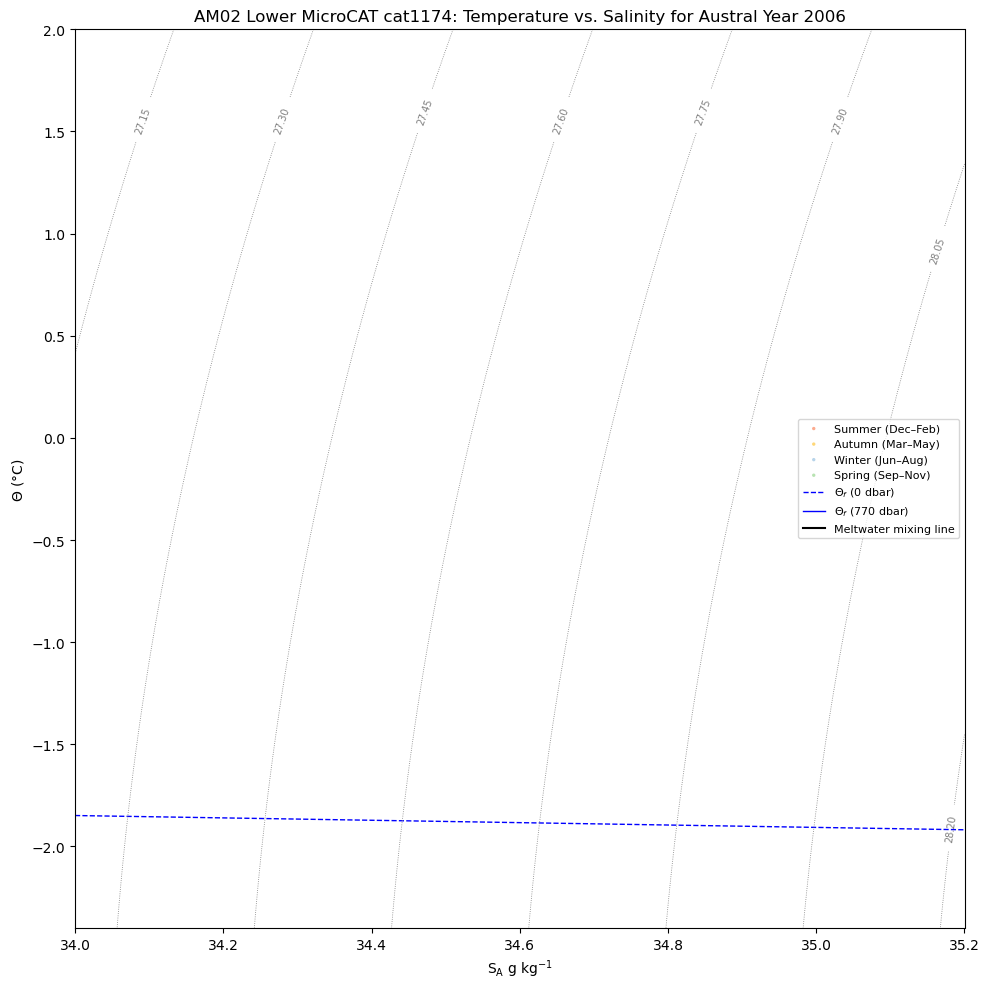

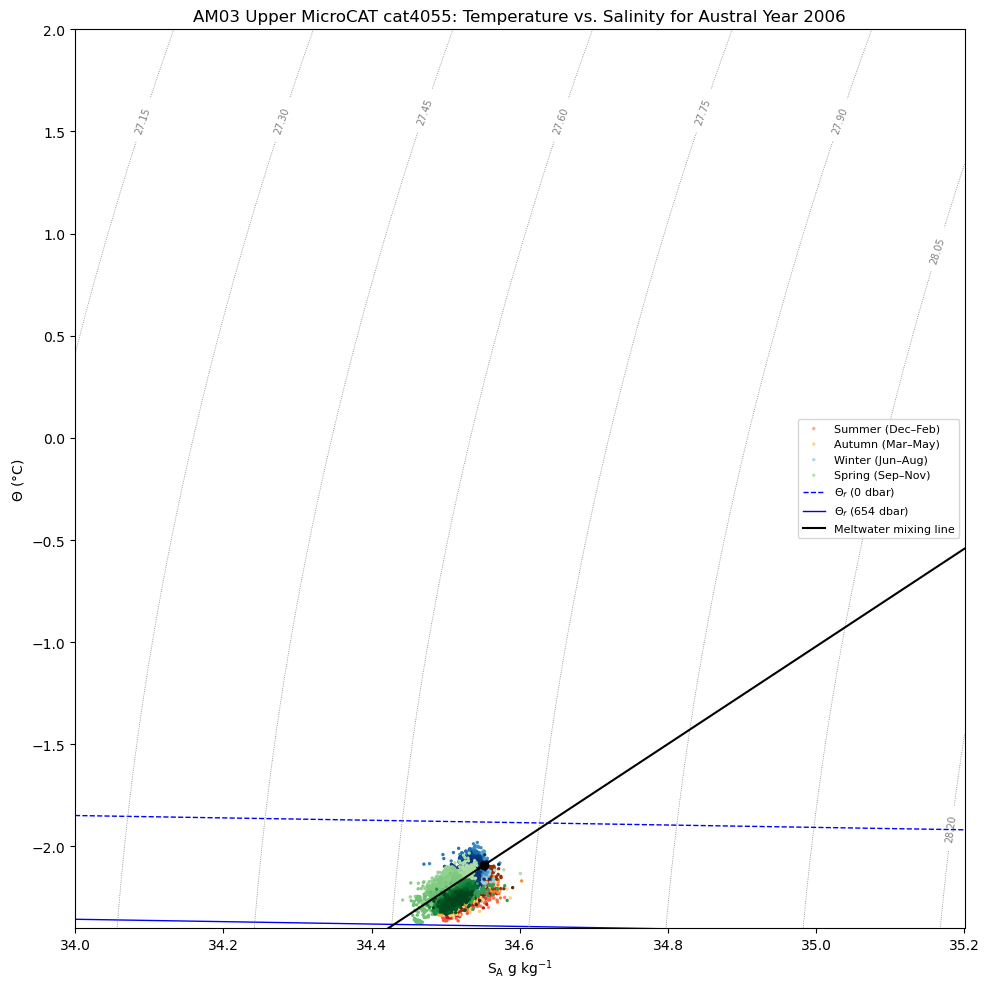

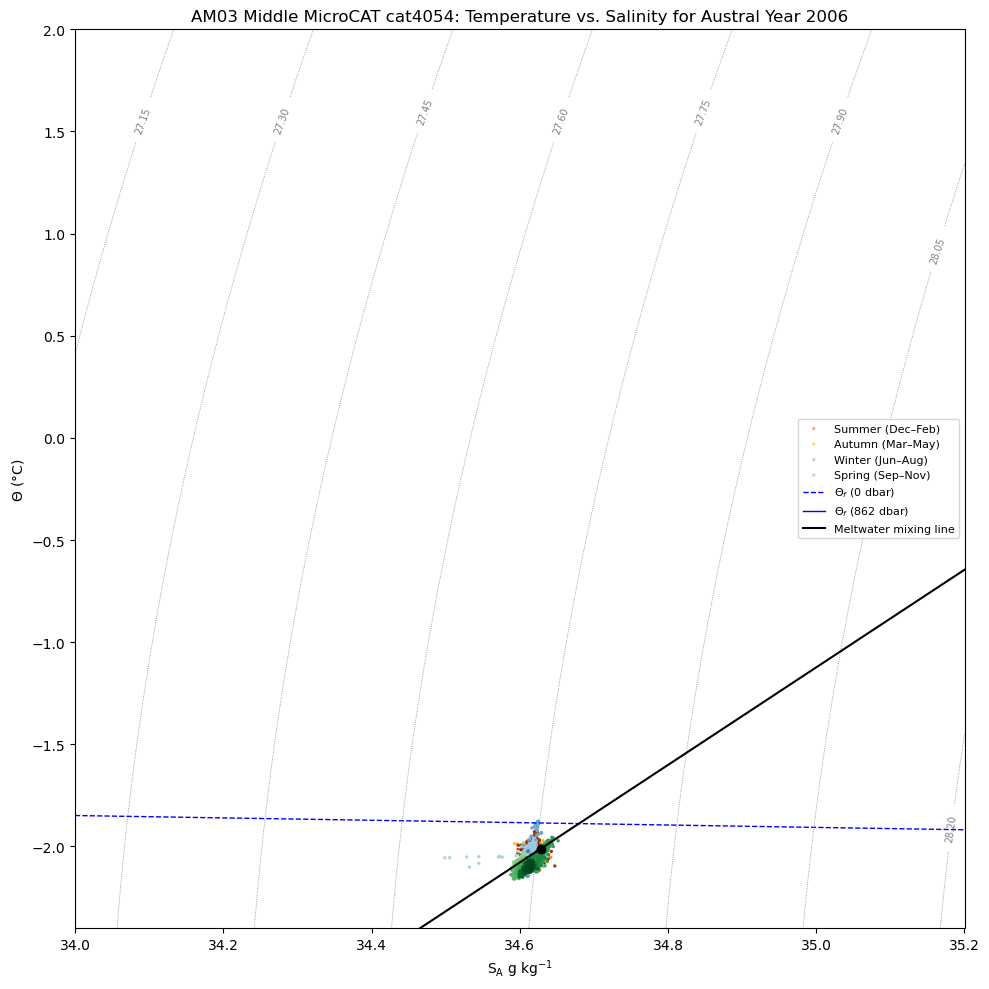

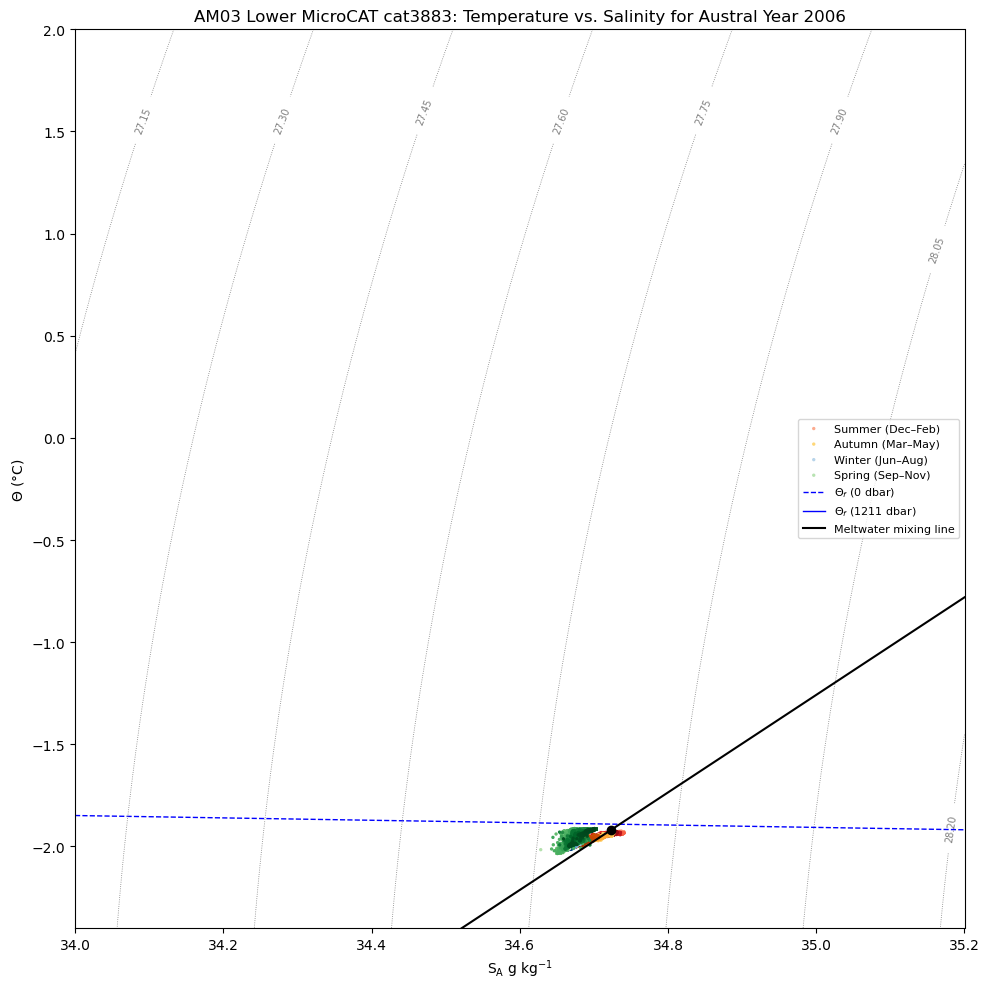

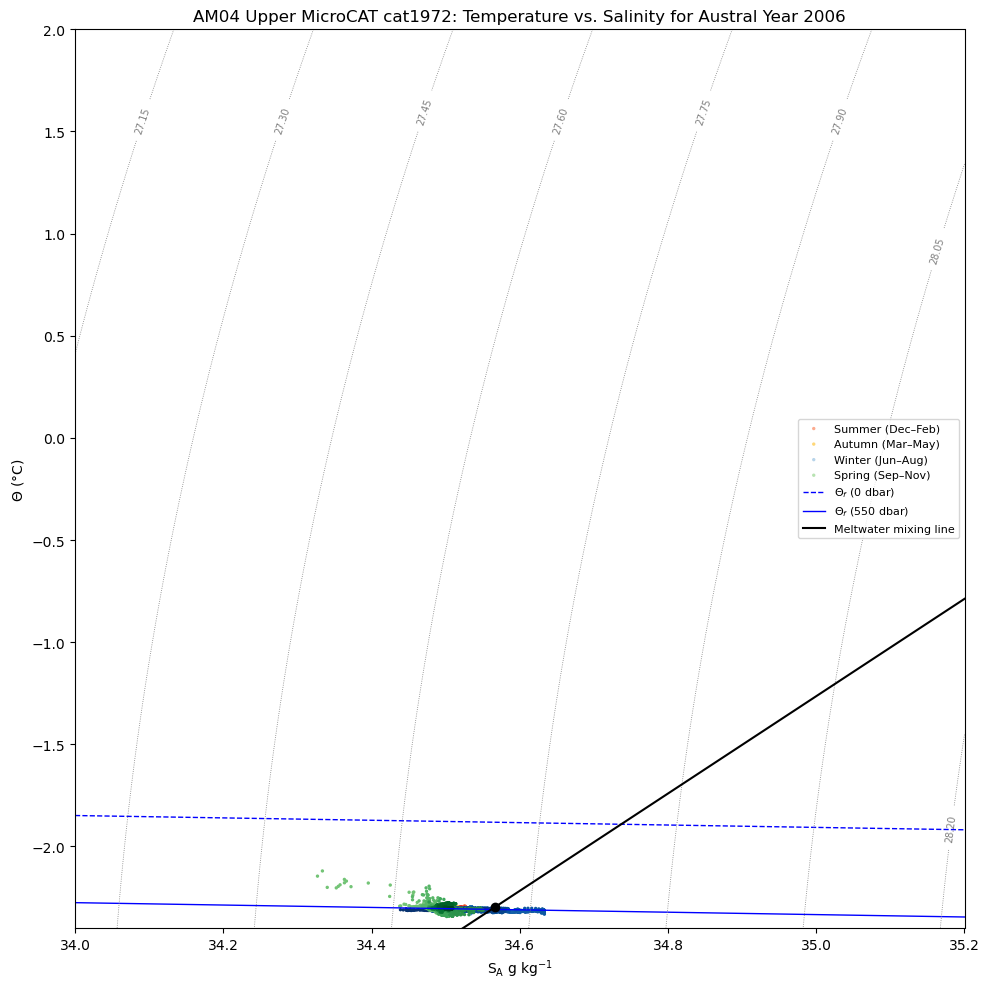

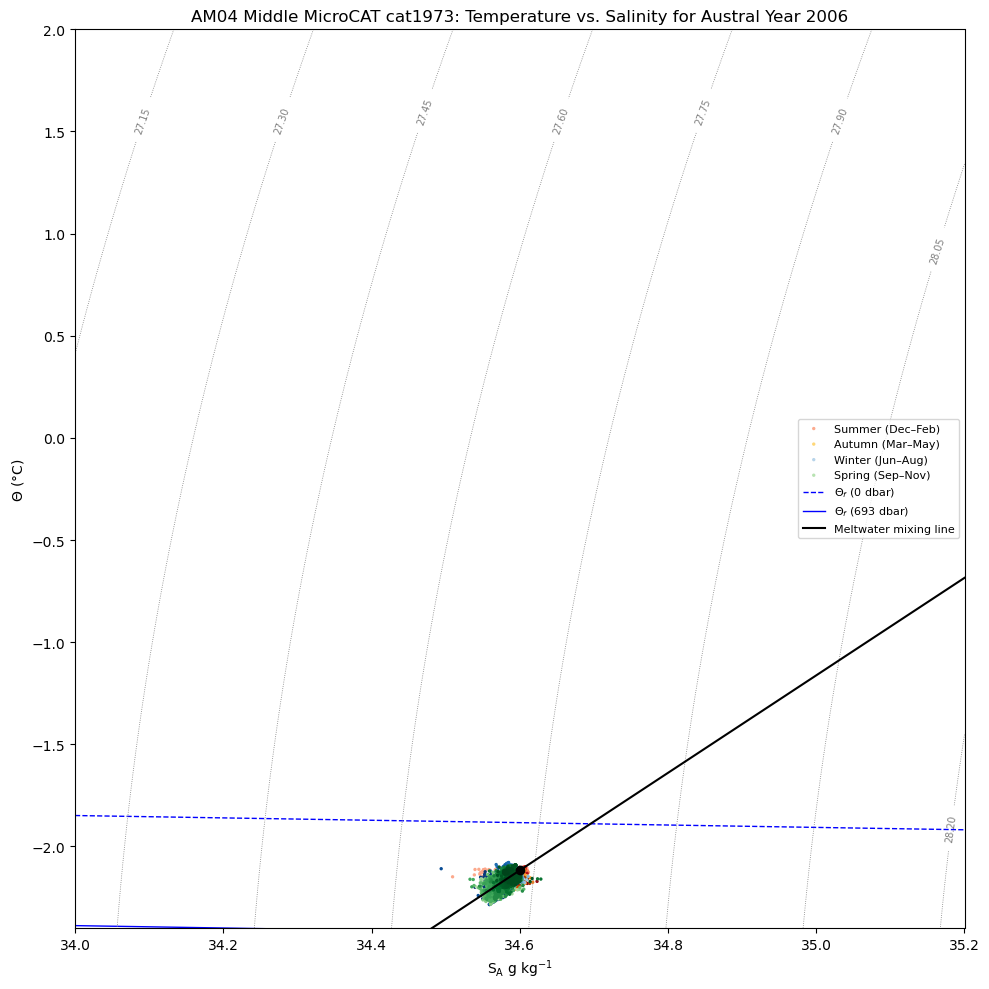

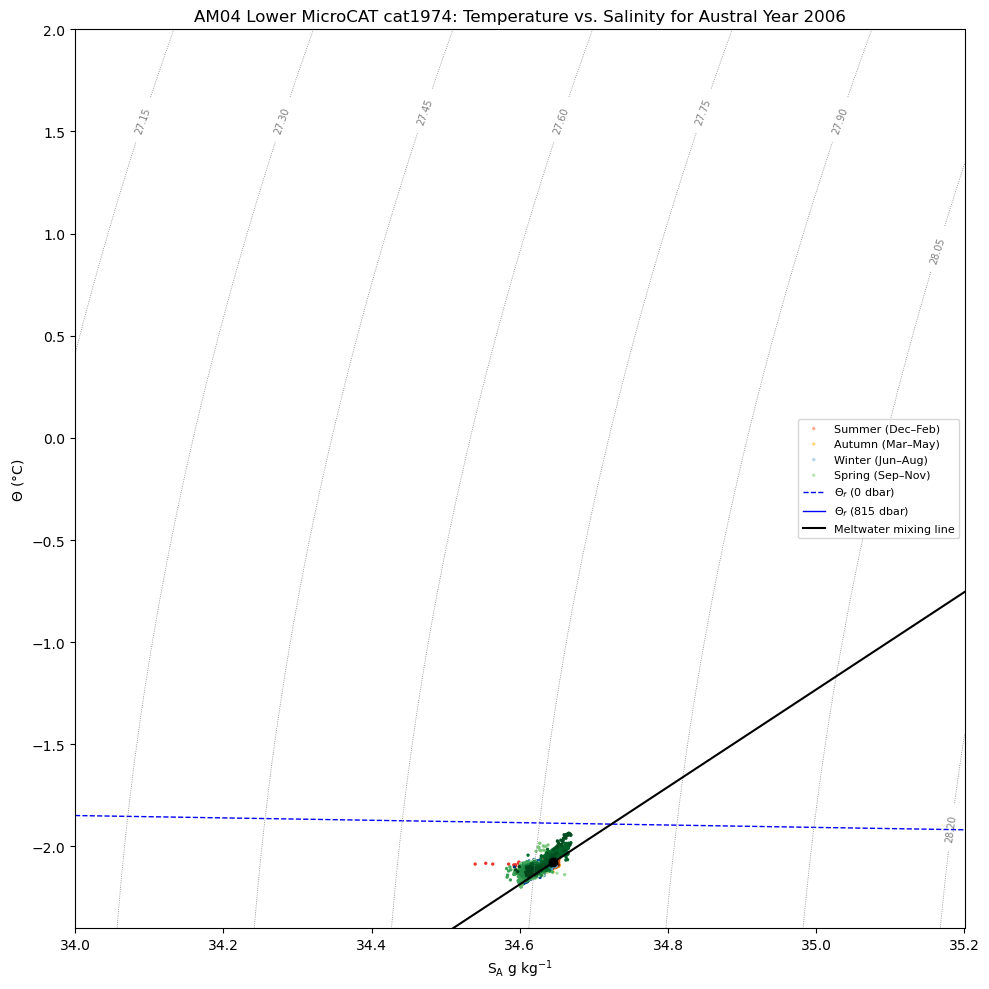

No data for AM05 cat7327 in austral year 2006
No data for AM05 cat7326 in austral year 2006
No data for AM05 cat7322 in austral year 2006
No data for AM06 cat7325 in austral year 2006
No data for AM06 cat7324 in austral year 2006
No data for AM06 cat7323 in austral year 2006


In [22]:
df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Define the limits for plots of temperature and salinity
ylim_temp = (-2.4, 2.0)
xlim_sal = (34, 35.2)

target_year = 2006

boreholes = sorted(df["borehole"].unique())

for borehole in boreholes:
    df_bh = df[df["borehole"] == borehole]

    # Build a list to force ordered plotting of the upper, then middle, then lower MicroCAT
    position_order = ["upper", "middle", "lower"]

    for position in position_order:
        cats = df_bh[df_bh["water_column_position"] == position]["cat"].unique()

        for cat in cats:
            plot_ts_year(df, borehole, cat, target_year, ylim_temp=ylim_temp, xlim_sal=xlim_sal)